# 07 | Why does stricter censoring reverse SC–FC coupling?

**Learning goals:** separate frame selection from nuisance refitting; match retained exposure and motion; distinguish SC support from FC changes; interpret conditional resampling without claiming a treatment effect.

**Primary FC stability:** notebook 14 recommends 97 distinct frames per session from nonreplacement ten-frame blocks, with complete WM/CSF nuisance refitting. These equal-duration subset ranges are conditional stability summaries, not full-run confidence intervals. The observed full-run points remain unchanged. Notebooks 10/11/13 retain earlier bootstrap, matching and mechanism analyses as sensitivities. See `config/PRIMARY_FC_RESAMPLING.md`. **Current SC policy:** graphs, network means and simulations use each session's 16/20 consensus with mean counts per 10,000 attempted seeds. Primary paired coupling uses the 823-edge intersection with session-specific weights. See `config/PRIMARY_SC.md`. Historical seed-160 diagnostics in notebooks 07/08 remain sensitivity analyses; notebook 09 supplies the reliability evidence. Notebook 10 quantifies joint seed/FC sampling under this policy, including matched designs and support reselection. Notebook 11 extends the full-run branch to paired nuisance refits; notebook 12 integrates all clinical/context fields with network uncertainty. Notebook 13 diagnoses PCA-training shifts and compares nonreplacement blocks at matched distinct counts and 80% retention. The rule is post hoc and does not validate anatomy or a surgical/cognitive effect.

In [1]:
from pathlib import Path
import os, sys, json
root = Path.cwd() if (Path.cwd()/"pyproject.toml").exists() else Path.cwd().parent
os.environ.setdefault("MPLCONFIGDIR", str(root/".cache/matplotlib"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, Markdown, Image
from pat16 import ROOT, DATA, RESULTS, SESSIONS
from pat16.connectivity import labels
from pat16.primary_sc import load_weights
nodes = pd.read_csv(RESULTS/"nodes.csv")
summary = json.loads((RESULTS/"summary.json").read_text())
plt.rcParams.update({"figure.figsize": (9,4), "font.size": 10})


In [2]:
display(pd.read_csv(RESULTS/"primary_sc/censoring_decomposition.csv"))
display(pd.read_csv(RESULTS/"primary_sc/matched_coupling_summary.csv"))
print("Current common-consensus coupling has negative primary and strict point contrasts. The original reversal investigation below is retained as a historical sensitivity.")

,stage,pre_rho,post_rho,delta,edges
0,primary,0.188216,0.146488,-0.041728,823
1,restriction,0.150455,0.128630,-0.021825,823
2,coefficients,0.160203,0.125666,-0.034537,823
3,pca,0.160765,0.126526,-0.034239,823


,protocol,sc_reference,draws,median,q025,q975,positive_fraction
0,primary_duration,consensus80_common,200,-0.033469,-0.102928,0.044188,0.210
1,primary_motion,consensus80_common,200,-0.034635,-0.127969,0.049752,0.180
2,primary_motion_time,consensus80_common,200,-0.038928,-0.109233,0.036841,0.180
3,strict_duration,consensus80_common,200,-0.041916,-0.082191,0.000716,0.030
4,strict_motion,consensus80_common,200,-0.047966,-0.089791,-0.015873,0.000
5,strict_motion_time,consensus80_common,200,-0.022171,-0.055715,0.009081,0.085


Current common-consensus coupling has negative primary and strict point contrasts. The original reversal investigation below is retained as a historical sensitivity.


## Define the contrast before explaining it
In the historical seed-160 own-support experiment, the anatomical5 pipeline uses FD≤0.5 mm plus following-frame censoring, 146/150 frames and 107/111 algebraic residual df. Coupling is 0.2101→0.1894 (post−pre **−0.0207**). Strict FD≤0.3 mm retains 68/96 frames, 29/57 df, and refits tissue PCA: 0.1564→0.1675 (**+0.0111**). Both use the same corrected images, cortical ROIs, motion and session SC. A smaller mean FC is not equivalent to lower SC–FC rank coupling.

The historical experiments below used original seed-160 SC and left the then-primary matrices unchanged. Their coupling uses each session's own nonzero SC edges (1515/1559), with no graph-density threshold. The SC-support controls below explicitly change that estimand. No model is chosen from cognition or a preferred sign.

,session,pool,frames,retained_minutes,mean_retained_fd_mm,median_retained_fd_mm,max_retained_fd_mm,span_minutes,runs,adjacent_pairs,third_1,third_2,third_3,first_half
0,preop,primary,146,5.84,0.286852,0.263895,0.495078,7.00,9,137,52,47,47,75
1,preop,strict,68,2.72,0.216954,0.217031,0.296886,6.96,15,53,35,12,21,46
2,postop,primary,150,6.00,0.252216,0.232029,0.496175,6.92,10,140,54,52,44,81
3,postop,strict,96,3.84,0.208805,0.210386,0.299622,6.76,17,79,39,34,23,57


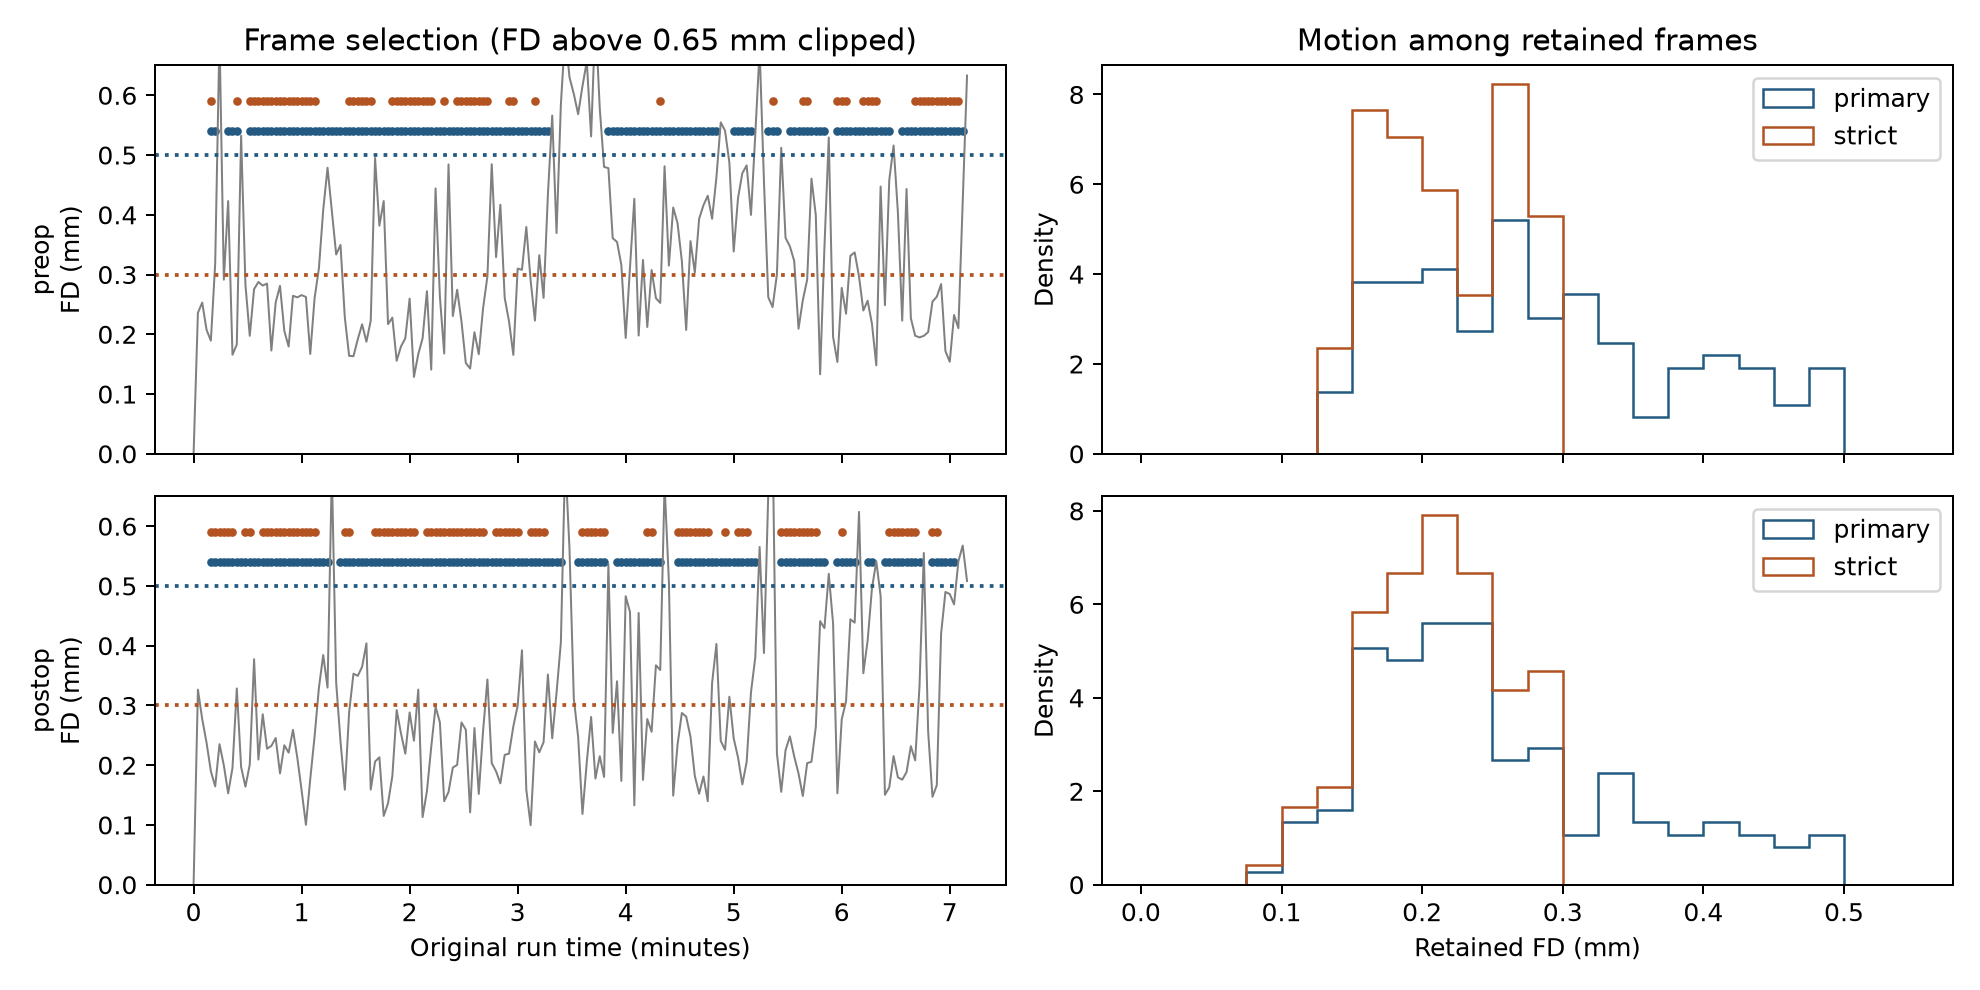

In [3]:
from pat16.censoring import OUT, PROTOCOLS, LABELS, show_draw
spec=json.loads((OUT/"design.json").read_text())
frame_qc=pd.read_csv(OUT/"frame_qc.csv")
display(frame_qc)
display(Image(filename=str(RESULTS/"figures/censoring_frame_qc.png")))

### Shorter exposure and different temporal coverage
Strict retained-frame mean FD is 0.2170/0.2088 mm (pre/post), versus 0.2869/0.2522 primarily. These are **retained-frame** summaries; the original main QC reports mean FD over all frames after the initial four. Strict censoring retains 35/12/21 pre-op frames in acquisition thirds, versus 39/34/23 post-op; 46/68 pre-op frames lie in the first half. The remaining samples span 6.96/6.76 minutes, but provide only 2.72/3.84 minutes of retained exposure. Retained exposure, acquisition span, run fragmentation and independent sample size are different quantities. Scan length and acquisition span both influence FC reliability (Birn et al., 2013; report bibliography).

## An ordered computational decomposition
First restrict **already denoised primary residuals** to strict frames; next refit final regression coefficients while keeping primary PCs fixed; finally refit tissue temporal projection/scaling/PCA on strict frames. These increments are order dependent. Frozen-fit controls use training observations outside the selected subset and are diagnostic, not independent short-run pipelines.

,session,stage,frames,residual_df,df_meaning,coupling,common_coupling,mean_fc
0,preop,primary,146,107,selected fit algebraic residual df,0.210147,0.203131,0.087228
1,preop,restriction,68,107,training residual df; subset effective df not ...,0.183541,0.170393,0.086527
2,preop,coefficients,68,29,selected fit algebraic residual df,0.167395,0.164907,0.056789
3,preop,pca,68,29,selected fit algebraic residual df,0.156366,0.165768,0.108481
4,postop,primary,150,111,selected fit algebraic residual df,0.189426,0.162970,0.045607
5,postop,restriction,96,111,training residual df; subset effective df not ...,0.171948,0.143015,0.041379
6,postop,coefficients,96,57,selected fit algebraic residual df,0.164683,0.133185,0.044777
7,postop,pca,96,57,selected fit algebraic residual df,0.167510,0.128179,0.041219


session,postop,preop,post_minus_pre
stage,,,
primary,0.189426,0.210147,-0.020720
restriction,0.171948,0.183541,-0.011593
coefficients,0.164683,0.167395,-0.002712
pca,0.167510,0.156366,0.011144


,session,mean_squared_canonical_correlation,squared_canonical_correlations
0,preop,0.634915,"[0.11262752941353446, 0.5485073955469892, 0.72..."
1,postop,0.739710,"[0.17598422818313872, 0.7235562458182515, 0.82..."


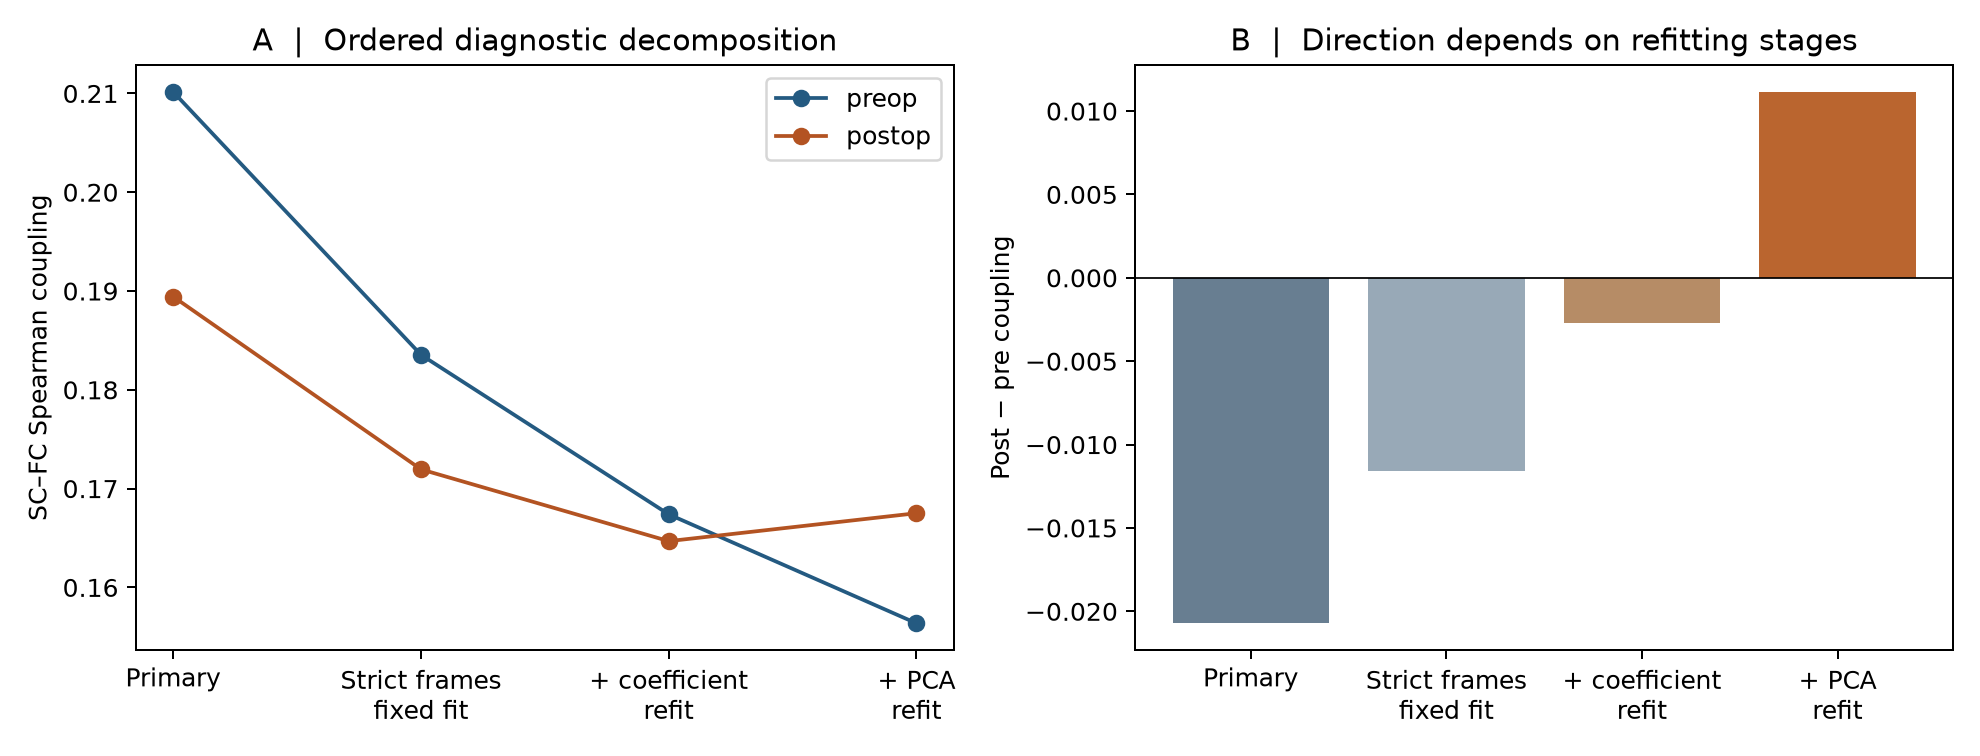

In [4]:
decomposition=pd.read_csv(OUT/"decomposition.csv")
display(decomposition[["session","stage","frames","residual_df","df_meaning","coupling","common_coupling","mean_fc"]])
delta=decomposition.pivot(index="stage",columns="session",values="coupling").loc[["primary","restriction","coefficients","pca"]]
delta["post_minus_pre"]=delta.postop-delta.preop
display(delta)
display(pd.DataFrame(json.loads((OUT/"pc_subspaces.json").read_text())))
display(Image(filename=str(RESULTS/"figures/censoring_decomposition.png")))

The contrast moves **−0.0207 → −0.0116 → −0.0027 → +0.0111**. Frame restriction alone does not reverse it. Refitting regression reduces coupling more preoperatively; retraining the five-PC subspace then crosses zero. Mean squared canonical correlations between primary/strict PC score subspaces centered on strict frames are 0.635 pre-op and 0.740 post-op. Signs and orthogonal basis rotations cannot cause a projection change. The strict pre-op fit has only 29 algebraic residual df; these are not autocorrelation-adjusted effective df. This sequence identifies computational dependencies, not noise versus neural truth.

## Matched designs: six protocols × 200 draws × two fitting modes
Every draw retains **68 frames/session**, without replacement, on the original 180-frame axis. Complete refits retrain temporal nuisance preprocessing, scaling, PCA and final regression using only selected frames (39 rank, 29 residual df). Frozen mode holds **both primary PCs and final regression coefficients** fixed; only the correlation samples change.

For each primary/strict pool, compare duration-only uniform sampling, duration+FD matching, and duration+FD+run-half matching. FD matching uses randomized maximum-cardinality bipartite assignment, a **0.015-mm absolute pairwise caliper**, then selection of 68 pairs. Half matching also gives equal counts within frames 0–89 and 90–179. No FC/SC/cognition determines selection. This targets common FD support, not uniform samples of the original pool, and matched frame pairs do not imply matching neural states.

Why this caliper? At 0.010 mm the strict pools permit 68 FD-only pairs but only 65 half-matched and 56 third-matched pairs; at 0.015 mm half matching permits 68, thirds only 60. We use 0.015 consistently for the motion controls. Half matching is a coarse temporal check, not exact time/state matching. The strict pre-op pool is exactly 68 frames and is unchanged across strict draws. This asymmetric conditional design is not participant resampling.

,protocol,mode,coupling_delta_median,coupling_delta_q025,coupling_delta_q975,coupling_positive_fraction,fd_abs_smd_median,fd_abs_smd_max_abs,fd_wasserstein_mm_median,first_half_count_difference_median
0,primary_duration,frozen,-0.023920,-0.058132,0.011006,0.110,0.355604,0.752861,0.034733,2.0
1,primary_duration,refit,-0.019866,-0.074438,0.043976,0.260,0.355604,0.752861,0.034733,2.0
2,primary_motion,frozen,-0.028673,-0.062934,-0.000487,0.020,0.019985,0.051695,0.005408,0.0
3,primary_motion,refit,-0.021533,-0.077100,0.039940,0.230,0.019985,0.051695,0.005408,0.0
4,primary_motion_time,frozen,-0.030394,-0.064349,-0.000094,0.025,0.015066,0.039149,0.005136,0.0
5,primary_motion_time,refit,-0.023972,-0.089676,0.027255,0.205,0.015066,0.039149,0.005136,0.0
6,strict_duration,frozen,-0.016591,-0.032383,-0.001577,0.015,0.168882,0.356111,0.008728,-6.0
7,strict_duration,refit,-0.006925,-0.038938,0.024629,0.355,0.168882,0.356111,0.008728,-6.0
8,strict_motion,frozen,-0.023120,-0.036640,-0.006650,0.000,0.012595,0.069289,0.003258,-6.0
9,strict_motion,refit,-0.013463,-0.043902,0.014357,0.175,0.012595,0.069289,0.003258,-6.0


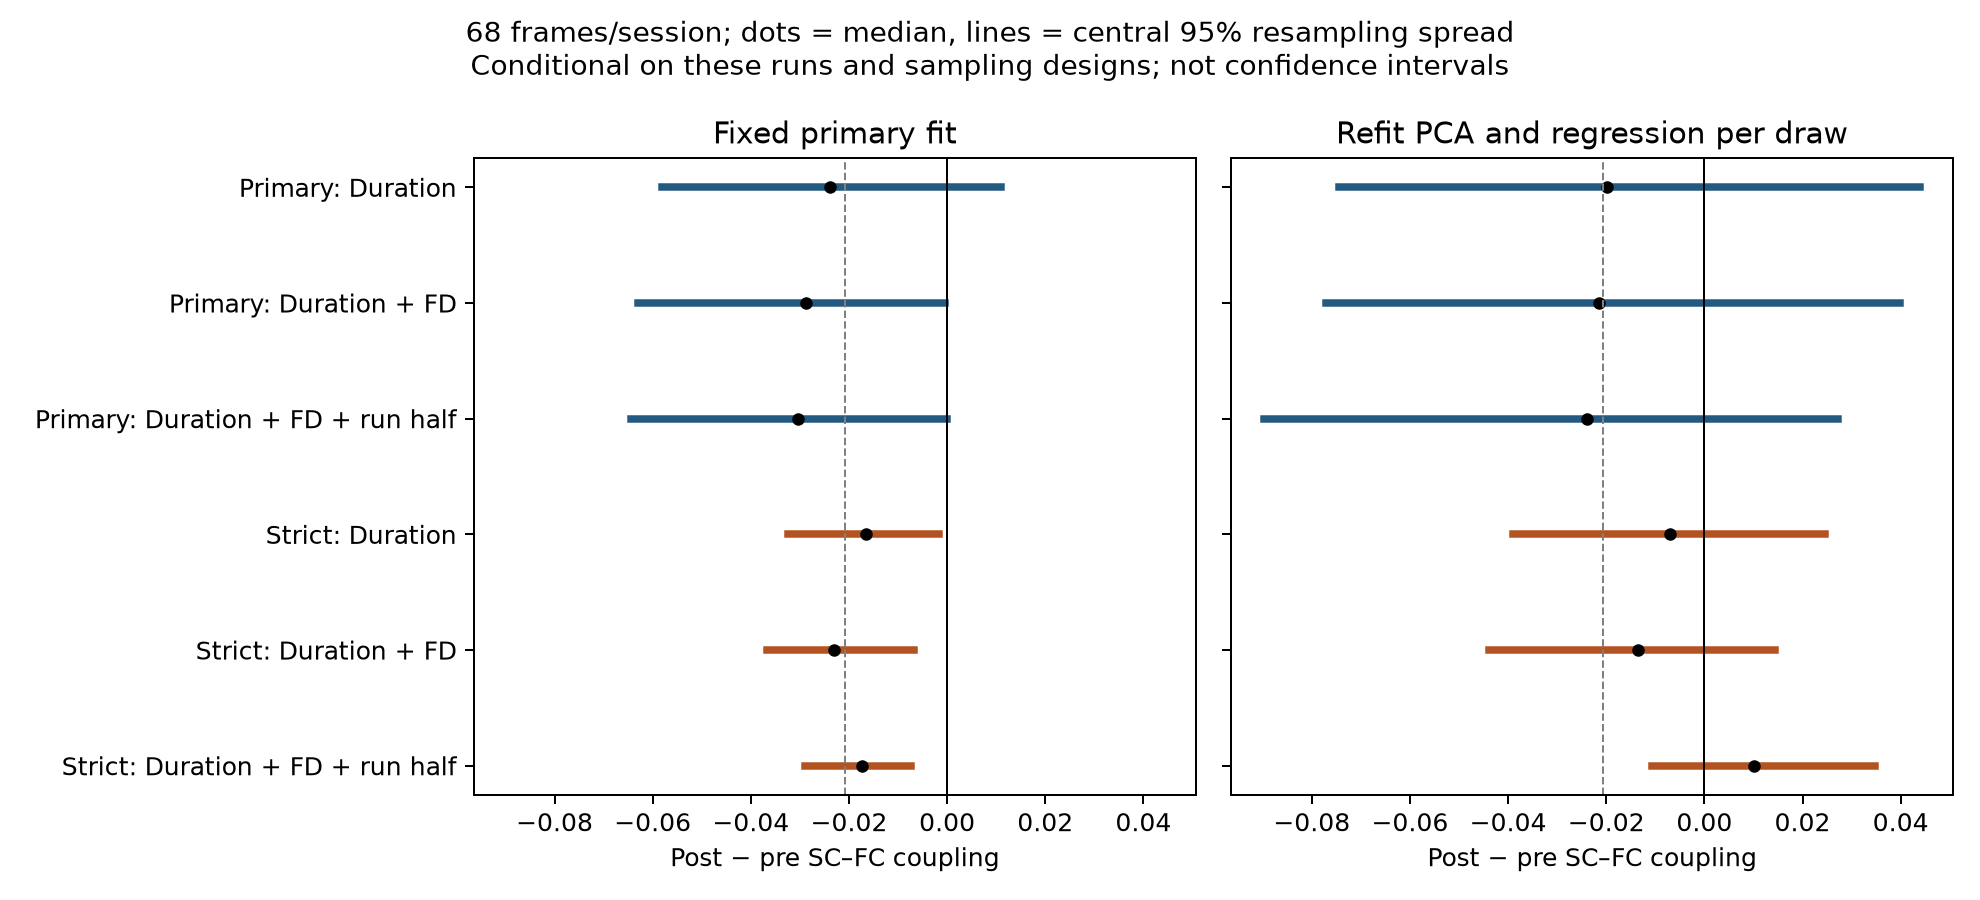

In [5]:
matched=pd.read_csv(OUT/"matched_replicates.csv")
matched_summary=pd.read_csv(OUT/"matched_summary.csv")
display(matched_summary[["protocol","mode","coupling_delta_median","coupling_delta_q025","coupling_delta_q975","coupling_positive_fraction","fd_abs_smd_median","fd_abs_smd_max_abs","fd_wasserstein_mm_median","first_half_count_difference_median"]])
display(Image(filename=str(RESULTS/"figures/censoring_matching.png")))

### What matching resolves—and what it does not
For full refits, primary-pool median changes remain negative (−0.0199 duration, −0.0215 duration+FD, −0.0240 with half matching), but every central range includes zero. Strict-pool medians are **−0.0069**, **−0.0135**, and **+0.0101**, respectively, with central ranges also spanning zero. FD-matched median absolute standardized differences are about 0.013–0.020 (all draws <0.070), much smaller than duration-only values. Balance on FD does not establish physiological equivalence or artifact removal.

The half control changes strict post-op first-half occupancy from a median 40 to exactly 46 frames, equal to pre-op. Its positive median with refitting, versus a negative frozen-fit median, shows that coarse time selection and nuisance refitting interact even after FD and frame counts are matched. The median third counts still differ: half matching cannot equate finer temporal coverage, fragmentation, autocorrelation or vigilance. The results therefore **do not isolate unequal duration as the sole explanation**, and do not establish neural recovery or decline.

The empirical 2.5/97.5 percentiles describe **conditional sampling-design spread**, not confidence intervals, probabilities of a surgery effect, p values or test–retest reliability. Single-frame draws do not model serial dependence. A high fraction of positive draws is descriptive only.

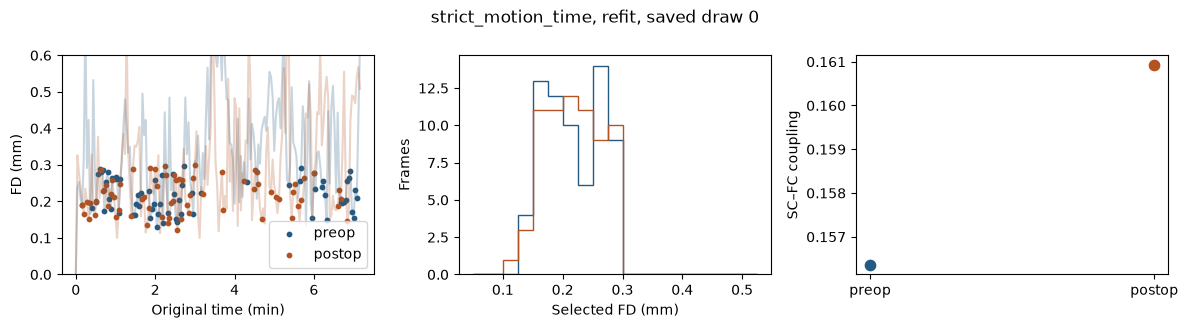

interactive(children=(Dropdown(description='protocol', index=5, options=('primary_duration', 'primary_motion',…

<function __main__.inspect_draw(protocol='strict_motion_time', mode='refit', replicate=0)>

In [6]:
def inspect_draw(protocol="strict_motion_time",mode="refit",replicate=0):
    fig=show_draw(protocol,mode,replicate);plt.show();plt.close(fig)
widgets.interact(inspect_draw,protocol=widgets.Dropdown(options=list(PROTOCOLS),value="strict_motion_time"),mode=widgets.Dropdown(options=["frozen","refit"],value="refit"),replicate=widgets.IntSlider(min=0,max=spec["repeats"]-1,value=0,continuous_update=False))

## Hold SC support fixed
The two own-SC supports have **1071 common nonzero edges**. Restricting to this intersection while retaining each session's weights yields primary coupling 0.2031→0.1630 (−0.0402) and strict coupling 0.1658→0.1282 (−0.0376): no reversal. Keeping **pre-op SC weights** fixed on that intersection instead yields +0.0064 primarily and +0.0019 strictly. These are distinct questions: own SC compares the two full reconstructed SC–FC associations; fixed pre-SC asks how FC aligns with a single structural reference. Neither is intrinsically the correct biological estimand.

Explore all three support/reference definitions on the same matched draws. The own-support reversal is not a universal property of FC, and the across-session SC reconstruction contributes to the measured contrast. Support controls do not establish whether changed SC edges are true anatomy or tractography variability.

,protocol,mode,common_coupling_delta_median,common_coupling_delta_q025,common_coupling_delta_q975,common_coupling_positive_fraction
1,primary_duration,refit,-0.033410,-0.106548,0.029791,0.150
3,primary_motion,refit,-0.037243,-0.111147,0.022328,0.105
5,primary_motion_time,refit,-0.041036,-0.107171,0.024399,0.110
7,strict_duration,refit,-0.045296,-0.081029,-0.009826,0.005
9,strict_motion,refit,-0.055718,-0.087921,-0.020222,0.000
11,strict_motion_time,refit,-0.030028,-0.056189,-0.000796,0.020


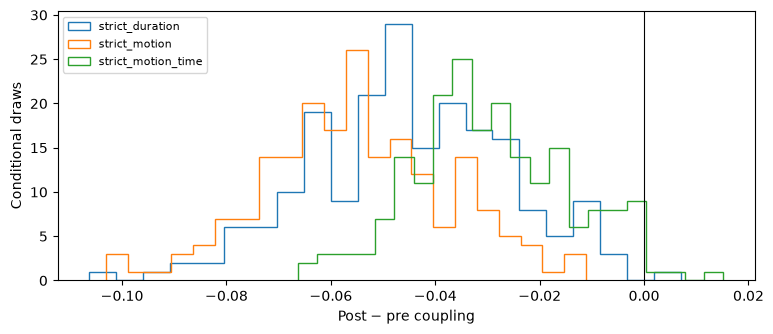

interactive(children=(Dropdown(description='reference', index=1, options=('coupling', 'common_coupling', 'fixe…

<function __main__.support_view(reference='common_coupling', mode='refit')>

In [7]:
display(decomposition.query("stage in ['primary','pca']")[["session","stage","coupling","common_coupling","fixed_pre_sc_coupling"]])
def support_view(reference="common_coupling",mode="refit"):
    cols=["protocol","mode",reference+"_delta_median",reference+"_delta_q025",reference+"_delta_q975",reference+"_positive_fraction"]
    display(matched_summary[matched_summary["mode"]==mode][cols])
    fig,ax=plt.subplots(figsize=(9,3.5))
    for p in ["strict_duration","strict_motion","strict_motion_time"]:
        g=matched[(matched.protocol==p)&(matched["mode"]==mode)]
        w=g.pivot(index="replicate",columns="session",values=reference)
        ax.hist(w.postop-w.preop,bins=22,histtype="step",label=p)
    ax.axvline(0,color="black",lw=.8);ax.set(xlabel="Post − pre coupling",ylabel="Conditional draws");ax.legend(fontsize=8);plt.show();plt.close(fig)
widgets.interact(support_view,reference=widgets.Dropdown(options=["coupling","common_coupling","fixed_pre_sc_coupling"],value="common_coupling"),mode=widgets.Dropdown(options=["frozen","refit"],value="refit"))

## Reproducibility and exercises
`uv run python scripts/investigate_censoring.py` reproduces 200 draws per protocol from bundled data, masks and SC, without rerunning FSL. `design.json` records source/code SHA256 and seeds; `matched_masks.npz` stores all selected masks in preop/postop order; CSVs contain every draw's balance, temporal coverage, mean FC and three coupling estimands. The code never overwrites primary or strict FC. See `config/CENSORING_MATCHING.md` for assumptions and feasibility. Earlier primary report/provenance and immutable-output hashes are under `before_matching`.

**Conclusion:** retain the existing FD0.5 anatomical5 primary strategy on methodological grounds, with the coupling direction explicitly unresolved across sensitivity designs. Do not select a censor threshold or SC reference from the desired sign. The result is compatible with interacting selection, small-sample regression/PCA and SC-support effects; no independent physiological or retest evidence identifies their biological components.

**Exercises:** compare frozen and fully refitted results for the same saved draw; compare motion-only versus half matching and inspect remaining third-count differences; change the SC reference without changing FC; explain why 68 frames with rank 39 do not supply 29 independent neural observations. Which additional BOLD runs, physiological recordings or repeat SC reconstructions would discriminate these explanations? Continue in notebook [08](08_edges_networks_and_coupling_reversal.ipynb) to inspect individual edge contributions, shared/session-specific supports and network-pair/deletion controls.